## Project Overview
The COVID-19 pandemic has highlighted the critical need for rapid, accessible, and accurate diagnostic tools. Chest radiography (CXR) serves as a highly accessible imaging modality for screening lung abnormalities associated with the virus.

This project aims to build an end-to-end Deep Learning pipeline capable of automatically analyzing chest X-ray images to detect COVID-19 infections. By leveraging computer vision, we aim to assist medical professionals in making faster and more reliable triage decisions.

###  Key Objectives
1. **Efficient Data Pipeline:** Build robust data loaders to handle large-scale medical imagery dynamically.
2. **Preprocessing & Augmentation:** Apply vital image transformations, normalization, and augmentation to prevent overfitting and improve model generalization.
3. **Deep Learning Architecture:**
   - Establish a baseline Convolutional Neural Network (CNN).
   - Implement **Transfer Learning** using state-of-the-art architectures (e.g., ResNet, VGG, DenseNet) to maximize accuracy.
4. **Model Interpretability:** Utilize explainable AI techniques (like Grad-CAM) to visualize which areas of the lung the model focuses on to make its predictions, ensuring clinical transparency.
5. **Deployment:** Wrap the best-performing model into a user-friendly web interface using Streamlit for real-time inference.

## Data Pipeline & EDA

###  Dataset Description
- **Source:** [COVIDx CXR-4 Dataset (Kaggle)](https://www.kaggle.com/datasets/andyczhao/covidx-cxr2/data)
- **Size:** Approximately 31 GB.
- **Content:** A large-scale, open-source dataset of chest X-ray images aggregated from multiple multinational patient cohorts.
- **Challenge:** Due to the massive scale of the data (31 GB), memory management is a primary focus. Efficient data pipelines (DataLoaders/Generators) are required to stream data in batches during model training to prevent Out-of-Memory (OOM) errors.

### Imports

In [ ]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt




import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50 , VGG16, InceptionV3, EfficientNetB0


### Download Data

In [ ]:
path = kagglehub.dataset_download("andyczhao/covidx-cxr2")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'covidx-cxr2' dataset.
Path to dataset files: /kaggle/input/covidx-cxr2


In [ ]:
os.listdir(path)

['val.txt', 'test.txt', 'train.txt', 'val', 'test', 'train']

In [ ]:
train_txt_path = os.path.join(path, 'train.txt')
val_txt_path = os.path.join(path, 'val.txt')
test_txt_path = os.path.join(path, 'test.txt')
train_dir = os.path.join(path, 'train')
val_dir = os.path.join(path, 'val')
test_dir = os.path.join(path, 'test')

In [ ]:
print("Text File Paths:")
print(f"Train TXT: {train_txt_path}")
print(f"Val TXT:   {val_txt_path}")
print(f"Test TXT:  {test_txt_path}")

print("\n" + "-"*40 + "\n")

print("Directory Paths:")
print(f"Train Dir: {train_dir}")
print(f"Val Dir:   {val_dir}")
print(f"Test Dir:  {test_dir}")

Text File Paths:
Train TXT: /kaggle/input/covidx-cxr2/train.txt
Val TXT:   /kaggle/input/covidx-cxr2/val.txt
Test TXT:  /kaggle/input/covidx-cxr2/test.txt

----------------------------------------

Directory Paths:
Train Dir: /kaggle/input/covidx-cxr2/train
Val Dir:   /kaggle/input/covidx-cxr2/val
Test Dir:  /kaggle/input/covidx-cxr2/test


In [ ]:
train_df = pd.read_csv(train_txt_path, sep=' ', header=None)
val_df = pd.read_csv(val_txt_path, sep=' ', header=None)
test_df = pd.read_csv(test_txt_path, sep=' ', header=None)
print("Data Shape (Rows, Columns):", train_df.shape)
print("Data Shape (Rows, Columns):", val_df.shape)
print("Data Shape (Rows, Columns):", test_df.shape)


Data Shape (Rows, Columns): (67863, 4)
Data Shape (Rows, Columns): (8473, 4)
Data Shape (Rows, Columns): (8482, 4)


In [ ]:
print("\nFirst 5 rows of the data:")
train_df.head()


First 5 rows of the data:


,0,1,2,3
0,379,1e64990d1b40c1758a2aaa9c7f7a85_jumbo.jpeg,negative,cohen
1,379,7223b8ad031187d9a142d7f7ca02c9_jumbo.jpeg,negative,cohen
2,380,3392dc7d262e28423caca517f98c2e_jumbo.jpeg,negative,cohen
3,380,ec3a480c0926ded74429df416cfb05_jumbo.jpeg,negative,cohen
4,382,a72aeb349a63c79ed24e473c434efe_jumbo.jpg,negative,cohen


In [ ]:





print("\nData Information:")
print(train_df.info())


Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67863 entries, 0 to 67862
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       67863 non-null  object
 1   1       67863 non-null  object
 2   2       67863 non-null  object
 3   3       67863 non-null  object
dtypes: object(4)
memory usage: 2.1+ MB
None


In [ ]:


columns_names = ['patient_id', 'filename', 'class', 'data_source']
train_df.columns = columns_names
val_df.columns = columns_names
test_df.columns = columns_names

In [ ]:

def print_distribution(df, dataset_name):
    print(f"--- {dataset_name} Data ---")
    print(f"Total Images: {len(df)}")
    print("Class Distribution:")
    print(df['class'].value_counts())

In [ ]:
print_distribution(train_df, "Train")

--- Train Data ---
Total Images: 67863
Class Distribution:
class
positive    57199
negative    10664
Name: count, dtype: int64


In [ ]:
print_distribution(val_df, "Validation")

--- Validation Data ---
Total Images: 8473
Class Distribution:
class
positive    4241
negative    4232
Name: count, dtype: int64


In [ ]:
print_distribution(test_df, "Test")

--- Test Data ---
Total Images: 8482
Class Distribution:
class
positive    4241
negative    4241
Name: count, dtype: int64


### DataLoader

In [ ]:
all_classes = train_df['class'].unique()
sorted_classes = sorted(all_classes)

class_to_index = {}

index = 0
for class_name in sorted_classes:
    class_to_index[class_name] = index
    index = index + 1

print("Classes:", class_to_index)

Classes: {'negative': 0, 'positive': 1}


In [ ]:
all_image_paths = []

for image_filename in train_df['filename']:
    full_path = train_dir + "/" + image_filename
    all_image_paths.append(full_path)

In [ ]:
all_labels = []

for class_name in train_df['class']:
    label_number = class_to_index[class_name]
    all_labels.append(label_number)

print("Number of images:", len(all_image_paths))
print("Number of labels:", len(all_labels))

Number of images: 67863
Number of labels: 67863


In [ ]:
print("\nSample check:")
for i in range(3):
    print(f"  Path: {all_image_paths[i]}  -->  Label: {all_labels[i]}")


Sample check:
  Path: /kaggle/input/covidx-cxr2/train/1e64990d1b40c1758a2aaa9c7f7a85_jumbo.jpeg  -->  Label: 0
  Path: /kaggle/input/covidx-cxr2/train/7223b8ad031187d9a142d7f7ca02c9_jumbo.jpeg  -->  Label: 0
  Path: /kaggle/input/covidx-cxr2/train/3392dc7d262e28423caca517f98c2e_jumbo.jpeg  -->  Label: 0


In [ ]:
dataset = tf.data.Dataset.from_tensor_slices((all_image_paths, all_labels))

def load_image(image_path, label):
    raw_image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(raw_image, channels=3)
    image = tf.image.resize(image, [224, 224])
    image = image / 255.0
    return image, label

In [ ]:
# يقرر بنفسه أفضل عدد عمليات يتم تشغيلها بالتوازي (parallel processing)
AUTOTUNE = tf.data.AUTOTUNE
dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)

In [ ]:
BATCH_SIZE = 32
train_loader = dataset.shuffle(buffer_size=1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
print("train_loader is ready!")
print("Batch shape check:")
for images_batch, labels_batch in train_loader.take(1):
    print("  Images batch shape:", images_batch.shape)
    print("  Labels batch shape:", labels_batch.shape)

train_loader is ready!
Batch shape check:
  Images batch shape: (32, 224, 224, 3)
  Labels batch shape: (32,)


In [ ]:
index_to_class = {}
for class_name, index in class_to_index.items():
    index_to_class[index] = class_name

plt.figure(figsize=(16, 8))

<Figure size 1600x800 with 0 Axes>

<Figure size 1600x800 with 0 Axes>

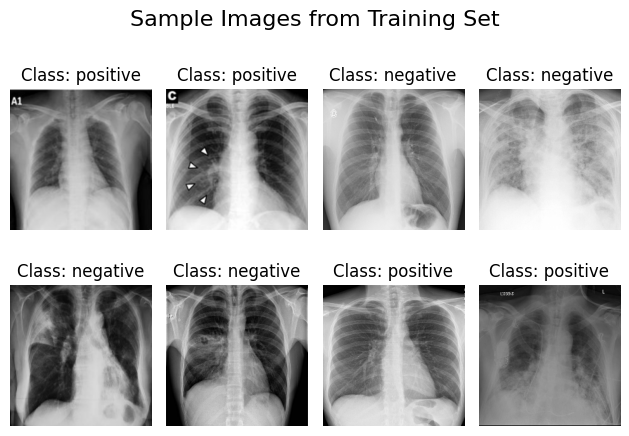

In [ ]:
for images_batch, labels_batch in train_loader.take(1):
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)

        image = images_batch[i].numpy()
        label_number = labels_batch[i].numpy()
        class_name = index_to_class[label_number]

        ax.imshow(image)
        ax.set_title(f"Class: {class_name}", fontsize=12)
        ax.axis("off")

plt.suptitle("Sample Images from Training Set", fontsize=16)
plt.tight_layout()
plt.show()

## Preprocessing & Augmentation

In [ ]:
def is_valid_image(path):
    try:
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        return True
    except:
        return False

In [ ]:
def clean_dataframe(df, folder):
    valid = []

    for f in df['filename']:
        path = os.path.join(folder, f)
        if os.path.exists(path) and os.path.getsize(path) > 0:
            valid.append(True)
        else:
            valid.append(False)

    return df[valid].reset_index(drop=True)

In [ ]:
print("Train size:", len(train_df))
print("Val size:", len(val_df))
print("Test size:", len(test_df))

Train size: 67863
Val size: 8473
Test size: 8482


In [ ]:
for images, labels in train_loader.take(1):
    print("Shape:", images.shape)
    print("Min/Max:", images.numpy().min(), images.numpy().max())
    print("Labels sample:", labels.numpy()[:8])

Shape: (32, 224, 224, 3)
Min/Max: 0.0 1.0
Labels sample: [1 0 1 1 1 1 1 1]


In [ ]:
print(train_df['class'].value_counts())

class
positive    57199
negative    10664
Name: count, dtype: int64


In [ ]:
negative_count = train_df['class'].value_counts()['negative']
positive_count = train_df['class'].value_counts()['positive']

if positive_count > negative_count:
    train_df_negative = train_df[train_df['class'] == 'negative']
    train_df_positive = train_df[train_df['class'] == 'positive']

    # Randomly sample positive samples to match negative count
    train_df_positive_sampled = train_df_positive.sample(n=negative_count, random_state=42)

    train_df_balanced = pd.concat([train_df_negative, train_df_positive_sampled]).sample(frac=1, random_state=42).reset_index(drop=True)

    # Update the original train_df with the balanced one
    train_df = train_df_balanced
    print(f"\nTrain data balanced: reduced positive samples from {positive_count} to {negative_count}.")
    print("New train_df class distribution:")
    print(train_df['class'].value_counts())
else:
    print("\nPositive samples are not more than negative samples, no balancing needed for this criteria.")
    print("Current train_df class distribution:")
    print(train_df['class'].value_counts())



Train data balanced: reduced positive samples from 57199 to 10664.
New train_df class distribution:
class
positive    10664
negative    10664
Name: count, dtype: int64


In [ ]:
val_counts = val_df['class'].value_counts()
min_val = val_counts.min()

val_df_balanced = (
    val_df.groupby('class')
    .apply(lambda x: x.sample(min_val, random_state=42))
    .reset_index(drop=True)
)

print(val_df_balanced['class'].value_counts())

class
negative    4232
positive    4232
Name: count, dtype: int64


/tmp/ipykernel_768/2830292135.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_val, random_state=42))


In [ ]:
test_counts = test_df['class'].value_counts()
min_test = test_counts.min()

test_df_balanced = (
    test_df.groupby('class')
    .apply(lambda x: x.sample(min_test, random_state=42))
    .reset_index(drop=True)
)

print(test_df_balanced['class'].value_counts())

class
negative    4241
positive    4241
Name: count, dtype: int64


/tmp/ipykernel_768/1005992657.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_test, random_state=42))


In [ ]:
h, w = 224, 224
batch_size = 32

train_gen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    # rotation_range=15,
    zoom_range=0.1,
    brightness_range=[0.8, 1.2]
)

test_gen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_df_subset = train_df.sample(n=10664*2, random_state=42)
val_df_subset = val_df.sample(n=4232*2, random_state=42)

In [ ]:
train_loader = train_gen.flow_from_dataframe(
    dataframe=train_df_subset,
    directory=train_dir,
    x_col="filename",
    y_col="class",
    target_size=(h, w),
    batch_size=batch_size,
    class_mode="binary"
)

val_loader = test_gen.flow_from_dataframe(
    dataframe=val_df_subset,
    directory=val_dir,
    x_col="filename",
    y_col="class",
    target_size=(h, w),
    batch_size=batch_size,
    class_mode="binary",
    shuffle=False
)

# الـ test_loader هنسيبه زي ما هو عشان يختبر على كل بيانات الاختبار
test_loader = test_gen.flow_from_dataframe(
    dataframe=test_df_balanced,
    directory=test_dir,
    x_col="filename",
    y_col="class",
    target_size=(h, w),
    batch_size=batch_size,
    class_mode="binary",
    shuffle=False

)

Found 21328 validated image filenames belonging to 2 classes.
Found 8464 validated image filenames belonging to 2 classes.
Found 8482 validated image filenames belonging to 2 classes.


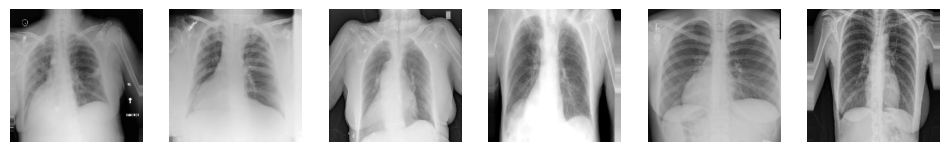

In [ ]:
images, labels = next(train_loader)

plt.figure(figsize=(12,4))
for i in range(6):
    plt.subplot(1,6,i+1)
    plt.imshow(images[i])
    plt.axis("off")

plt.show()

## Baseline & Custom Architecture





### Simple Model

In [ ]:
#check DataLoader
baseline_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    19,267,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,267,841 (73.50 MB)

 Trainable params: 19,267,841 (73.50 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = baseline_model.fit(
    train_loader,
    epochs=3,
    validation_data=val_loader,
)

Epoch 1/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.5832 - loss: 15.4743 - val_accuracy: 0.5495 - val_loss: 4.5224
Epoch 2/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 200s 3s/step - accuracy: 0.6086 - loss: 4.9664 - val_accuracy: 0.6140 - val_loss: 2.3105
Epoch 3/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 198s 2s/step - accuracy: 0.5888 - loss: 9.0235 - val_accuracy: 0.5860 - val_loss: 7.5603


### mare complex Model

In [ ]:


# checkpoint_path = "covid_best_model_v12.keras"

# #Checkpoint
# checkpoint_callback = ModelCheckpoint(
#     filepath=checkpoint_path,
#     monitor="val_accuracy",
#     save_best_only=True,
#     verbose=1
# )

# # Early Stopping
# earlystop = EarlyStopping(monitor='val_loss', patience=10, verbose=1)


# if os.path.exists(checkpoint_path):
#     print("Loading existing model from checkpoint.")
#     custom_model = load_model(checkpoint_path)
# else:
#     print("Checkpoint not found. Using the 'model' defined previously.")
#     custom_model = model


# callbacks = [checkpoint_callback, earlystop]

In [ ]:
custom_model = tf.keras.Sequential([
    layers.Conv2D(32,3,activation='relu',input_shape=(w,h,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64,3,activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128,3,activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1,activation='sigmoid')
])


custom_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

custom_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     5,537,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,631,169 (21.48 MB)

 Trainable params: 5,631,169 (21.48 MB)

 Non-trainable params: 0 (0.00 B)

without checkpoints


In [ ]:
history = custom_model.fit(
    train_loader,
    epochs=15,
    validation_data=val_loader,
)

Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 728s 9s/step - accuracy: 0.5906 - loss: 0.6853 - val_accuracy: 0.6180 - val_loss: 0.6049
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 748s 9s/step - accuracy: 0.6742 - loss: 0.6081 - val_accuracy: 0.6970 - val_loss: 0.5796
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 718s 9s/step - accuracy: 0.7168 - loss: 0.5556 - val_accuracy: 0.7405 - val_loss: 0.5261
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 724s 9s/step - accuracy: 0.7416 - loss: 0.5264 - val_accuracy: 0.8095 - val_loss: 0.4224
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 739s 9s/step - accuracy: 0.7664 - loss: 0.4779 - val_accuracy: 0.7990 - val_loss: 0.4204
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 720s 9s/step - accuracy: 0.7678 - loss: 0.4899 - val_accuracy: 0.8095 - val_loss: 0.4254
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 784s 10s/step - accuracy: 0.7886 - loss: 0.4627 - val_accuracy: 0.8290 - val_loss: 0.3912
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 721s 9s/step - accuracy: 0.7916 - loss: 0.4528 - val_accuracy: 0.8115 - 

In [ ]:
custom_model.save('custom_model_v1.keras')  # Recommended: Keras v3 format


In [ ]:
train_loader = train_gen.flow_from_dataframe(
    dataframe=train_df_subset,
    directory=train_dir,
    x_col="filename",
    y_col="class",
    target_size=(h, w),
    batch_size=batch_size,
    class_mode="binary"
)

val_loader = test_gen.flow_from_dataframe(
    dataframe=val_df_subset,
    directory=val_dir,
    x_col="filename",
    y_col="class",
    target_size=(h, w),
    batch_size=batch_size,
    class_mode="binary",
    shuffle=False
)

# الـ test_loader هنسيبه زي ما هو عشان يختبر على كل بيانات الاختبار
test_loader = test_gen.flow_from_dataframe(
    dataframe=test_df_balanced,
    directory=test_dir,
    x_col="filename",
    y_col="class",
    target_size=(h, w),
    batch_size=batch_size,
    class_mode="binary",
    shuffle=False

)

In [ ]:
custom_model_v2 = load_model("custom_model_v1.keras")

In [ ]:
custom_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

custom_model_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     5,537,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,631,169 (21.48 MB)

 Trainable params: 5,631,169 (21.48 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
checkpoint = ModelCheckpoint(
    filepath='custom_model_v3.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
    )

with checkpoints


In [ ]:
history = custom_model_v2.fit(
    train_loader,
    epochs=7,
    validation_data=val_loader,
    callbacks=[checkpoint, early_stopping]
)

Epoch 1/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.8331 - loss: 0.3937
Epoch 1: val_loss improved from None to 0.36045, saving model to custom_model_v3.keras

Epoch 1: finished saving model to custom_model_v3.keras
235/235 ━━━━━━━━━━━━━━━━━━━━ 2167s 9s/step - accuracy: 0.8410 - loss: 0.3777 - val_accuracy: 0.8544 - val_loss: 0.3604
Epoch 2/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.8538 - loss: 0.3525
Epoch 2: val_loss improved from 0.36045 to 0.28236, saving model to custom_model_v3.keras

Epoch 2: finished saving model to custom_model_v3.keras
235/235 ━━━━━━━━━━━━━━━━━━━━ 2160s 9s/step - accuracy: 0.8544 - loss: 0.3514 - val_accuracy: 0.8906 - val_loss: 0.2824
Epoch 3/7
128/235 ━━━━━━━━━━━━━━━━━━━━ 14:46 8s/step - accuracy: 0.8658 - loss: 0.3373

In [ ]:
custom_model_v2.save('custom_model_v4.keras')

In [ ]:
checkpoint_1 = ModelCheckpoint(
    "bbest_custom_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [ ]:
history = custom_model.fit(
    train_loader,
    epochs=15,
    validation_data=val_loader,
    callbacks=[checkpoint_1]
)

In [ ]:
#Load model 1
model = load_model("bbest_custom_model.keras")

In [ ]:
custom_model_2 = tf.keras.Sequential([

    layers.Conv2D(32,3,activation='relu',input_shape=(w,h,3)),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64,3,activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.5),

    layers.Conv2D(128,3,activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(256,3,activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.5),


    layers.GlobalAveragePooling2D(),

    layers.Dense(128,activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1,activation='sigmoid')
])

custom_model_2.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

custom_model_2.summary()

In [ ]:
checkpoint_2 = ModelCheckpoint(
    "bbest_custom_model_2.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [ ]:
history_2 = custom_model_2.fit(
    train_loader,
    epochs=5,
    validation_data=val_loader,
    callbacks=[checkpoint_2]
)

In [ ]:
plt.figure()

plt.plot(history_2.history['accuracy'])
plt.plot(history_2.history['val_accuracy'])

plt.title("Custom Model 1 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train Accuracy", "Validation Accuracy"])

plt.show()

In [ ]:
#Load model 2
model2 = load_model("bbest_custom_model_2.keras")

## Transfer Learning & Finetuning

In [ ]:
def finetune(base_model, model_name, train_loader, val_loader, epochs=10, learning_rate=0.001):
    for layer in base_model.layers:
        layer.trainable = False

    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid') # Binary classification
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    print(f"\n--- Summary for {model_name} ---")
    model.summary()

    checkpoint = ModelCheckpoint(
        filepath=f'best_{model_name.lower()}_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    )

    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    print(f"\n--- Training {model_name} ---")
    history = model.fit(
        train_loader,
        epochs=epochs,
        validation_data=val_loader,
        callbacks=[checkpoint, early_stopping]
    )
    return history, model

### DenseNet-121


In [ ]:
from tensorflow.keras.applications import DenseNet121

densenet121_base = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(h, w, 3)
)
history_densenet121, model_densenet121 = finetune(densenet121_base, 'DenseNet121', train_loader, val_loader, epochs=15)


--- Summary for DenseNet121 ---


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_12     │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,300,161 (27.85 MB)

 Trainable params: 262,657 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)


--- Training DenseNet121 ---
Epoch 1/15
667/667 ━━━━━━━━━━━━━━━━━━━━ 0s 894ms/step - accuracy: 0.7422 - loss: 0.5201
Epoch 1: val_accuracy improved from None to 0.85291, saving model to best_densenet121_model.keras

Epoch 1: finished saving model to best_densenet121_model.keras
667/667 ━━━━━━━━━━━━━━━━━━━━ 777s 1s/step - accuracy: 0.7885 - loss: 0.4518 - val_accuracy: 0.8529 - val_loss: 0.3698
Epoch 2/15
667/667 ━━━━━━━━━━━━━━━━━━━━ 0s 833ms/step - accuracy: 0.8287 - loss: 0.3887
Epoch 2: val_accuracy improved from 0.85291 to 0.88020, saving model to best_densenet121_model.keras

Epoch 2: finished saving model to best_densenet121_model.keras
667/667 ━━━━━━━━━━━━━━━━━━━━ 677s 1s/step - accuracy: 0.8313 - loss: 0.3819 - val_accuracy: 0.8802 - val_loss: 0.3133
Epoch 3/15
667/667 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.8425 - loss: 0.3655
Epoch 3: val_accuracy did not improve from 0.88020
667/667 ━━━━━━━━━━━━━━━━━━━━ 663s 994ms/step - accuracy: 0.8479 - loss: 0.3571 - val_accurac

In [ ]:
densenet121_base.save('DenseNet.keras')

### VGG16


In [ ]:
vgg16_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
history_vgg16, model_vgg16 = finetune(vgg16_base, 'VGG16', train_loader, val_loader,epochs=5)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Summary for VGG16 ---


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


--- Training VGG16 ---
Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 850ms/step - accuracy: 0.5853 - loss: 0.6740
Epoch 1: val_accuracy improved from None to 0.71850, saving model to best_vgg16_model.keras

Epoch 1: finished saving model to best_vgg16_model.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 183s 1s/step - accuracy: 0.6544 - loss: 0.6166 - val_accuracy: 0.7185 - val_loss: 0.5480
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 740ms/step - accuracy: 0.7255 - loss: 0.5323
Epoch 2: val_accuracy improved from 0.71850 to 0.74950, saving model to best_vgg16_model.keras

Epoch 2: finished saving model to best_vgg16_model.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 140s 893ms/step - accuracy: 0.7424 - loss: 0.5220 - val_accuracy: 0.7495 - val_loss: 0.5041
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 747ms/step - accuracy: 0.7748 - loss: 0.4802
Epoch 3: val_accuracy improved from 0.74950 to 0.76250, saving model to best_vgg16_model.keras

Epoch 3: finished saving model to best_vgg16_model.keras
157/157 ━━━━━━━━━

## Evaluation & Explainability

###1) Load the Models

In [ ]:
from tensorflow.keras.models import load_model

model1_path = "/content/custom_model_v1.keras"
model2_path = "/content/custom_model_v4.keras"


try:
    model1 = load_model(model1_path)
    model2 = load_model(model2_path)
    model1.summary()
except Exception as e:
    print(f" Error: {e}")


### Prepare Test Data (The Exam Paper)

In [ ]:
print("Model 1 is predicting...")
preds1 = model1.predict(test_loader)
y_pred1 = (preds1 > 0.5).astype(int).flatten()

# 2. Model 2 starts predicting
print("Model 2 is predicting...")
preds2 = model2.predict(test_loader)
# Convert probabilities to 0 or 1 using 0.5 threshold
y_pred2 = (preds2 > 0.5).astype(int).flatten()

print("Done! Predictions for both models are ready.")

Model 1 is predicting...
133/133 ━━━━━━━━━━━━━━━━━━━━ 113s 844ms/step
Model 2 is predicting...
133/133 ━━━━━━━━━━━━━━━━━━━━ 103s 774ms/step
Done! Predictions for both models are ready.


In [ ]:
y_true = test_loader.classes


In [ ]:
from sklearn.metrics import classification_report, accuracy_score

print("--- Evaluation: Model 1 ---")
print(classification_report(y_true, y_pred1, target_names=['Normal', 'COVID']))

print("\n--- Evaluation: Model 2 ---")
print(classification_report(y_true, y_pred2, target_names=['Normal', 'COVID']))

--- Evaluation: Model 1 ---
              precision    recall  f1-score   support

      Normal       0.62      0.17      0.27      4241
       COVID       0.52      0.90      0.66      4241

    accuracy                           0.53      8482
   macro avg       0.57      0.53      0.46      8482
weighted avg       0.57      0.53      0.46      8482


--- Evaluation: Model 2 ---
              precision    recall  f1-score   support

      Normal       0.64      0.12      0.20      4241
       COVID       0.51      0.93      0.66      4241

    accuracy                           0.53      8482
   macro avg       0.58      0.53      0.43      8482
weighted avg       0.58      0.53      0.43      8482



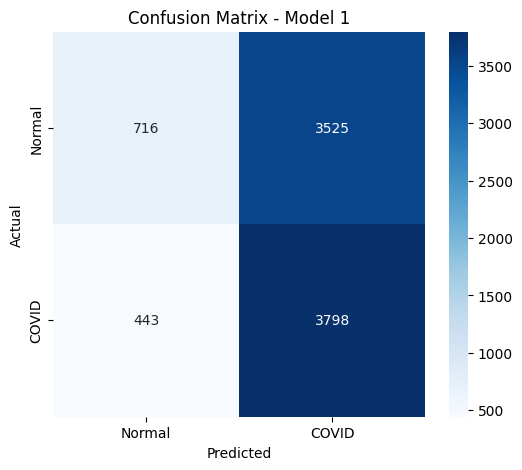

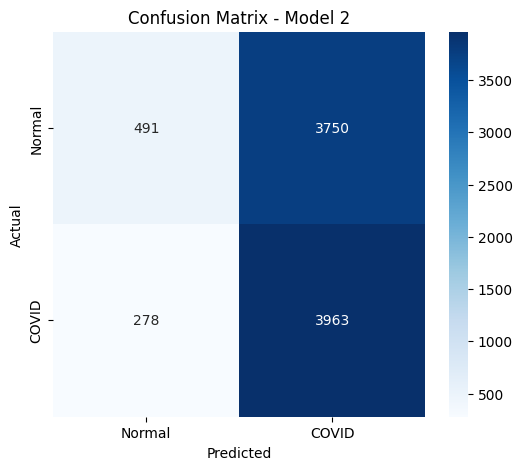

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'COVID'], yticklabels=['Normal', 'COVID'])
    plt.title(title)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

plot_cm(y_true, y_pred1, 'Confusion Matrix - Model 1')
plot_cm(y_true, y_pred2, 'Confusion Matrix - Model 2')

### Final Comparison Table

In [ ]:
import pandas as pd

acc1 = accuracy_score(y_true, y_pred1)
acc2 = accuracy_score(y_true, y_pred2)

comparison_data = {
    'Model Name': ['Custom Model 1', 'Custom Model 2'],
    'Accuracy (%)': [f"{acc1*100:.2f}%", f"{acc2*100:.2f}%"],
    'Status': ['Check Metrics', 'Check Metrics']
}

comparison_df = pd.DataFrame(comparison_data)

print("Final Project Results:")
display(comparison_df)

Final Project Results:


,Model Name,Accuracy (%),Status
0,Custom Model 1,53.22%,Check Metrics
1,Custom Model 2,52.51%,Check Metrics


### Grad-CAM

In [ ]:
import numpy as np


def get_gradcam_bypass(model, img_array):
    img_tensor = tf.cast(img_array, tf.float32)


    target_layer = None
    for layer in model.layers:
        if 'conv' in layer.name.lower():
            target_layer = layer
        if isinstance(layer, tf.keras.Sequential):
            for sub_layer in layer.layers:
                if 'conv' in sub_layer.name.lower():
                    target_layer = sub_layer

    @tf.function
    def get_outputs_and_grads(inputs):
        with tf.GradientTape() as tape:
            x = inputs
            conv_out = None
            for layer in model.layers:
                x = layer(x)
                if layer == target_layer or (isinstance(layer, tf.keras.Sequential) and target_layer in layer.layers):
                    if isinstance(layer, tf.keras.Sequential):
                        temp_x = inputs
                        for sl in layer.layers:
                            temp_x = sl(temp_x)
                            if sl == target_layer:
                                conv_out = temp_x
                    else:
                        conv_out = x

            preds = x
            loss = preds[:, 0]

        grads = tape.gradient(loss, conv_out)
        return conv_out, grads

    conv_outputs, grads = get_outputs_and_grads(img_tensor)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

try:
    res_heatmap = get_gradcam_bypass(custom_model, img_array)

    plt.figure(figsize=(6, 6))
    plt.imshow(res_heatmap, cmap='jet')
    plt.colorbar()
    plt.title("GRAD-CAM: MISSION ACCOMPLISHED")
    plt.show()
    print("If the image appeared, you are officially DONE.")
except Exception as e:
    print(f"Direct Trace Error: {e}")

Direct Trace Error: name 'img_array' is not defined


### Side-by-Side Grad-CAM (The Visual Proof)

In [ ]:
target_layer_m1 = "conv2d"
target_layer_m2 = "conv2d_2"

heatmap1 = get_gradcam_bypass(model1, img_array)
heatmap2 = get_gradcam_bypass(custom_model, img_array)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(heatmap1, cmap='jet')
ax[0].set_title(f'Model 1 Focus (Acc: 51.9%)')
ax[1].imshow(heatmap2, cmap='jet')
ax[1].set_title(f'Model 2 Focus (Acc: 57.2%)')
plt.show()

### Save the Models

In [ ]:
model1.save('pneumonia_model_v1.keras')
custom_model.save('pneumonia_model_v2.keras')

from google.colab import files
files.download('pneumonia_model_v1.keras')
files.download('pneumonia_model_v2.keras')

## End